<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Projections 2: Filters, Convolutions, & Transforms

### Question 1: CNN Intro (2)

In 150 words or less, describe the "tied weights" property of CNNs. Specifically, how are CNNs just neural networks where the weights are "shared" between features?

1) In 150 words or less, describe the "tied weights" property of CNNs. Specifically, how are CNNs just neural networks where the weights are "shared" between features? Why is the chain rule of differentiation is especially important calculating parameters in deep networks such a convolutional neural network? [PROMPT: Give a good high-level explanation of how a CNN works]

A Convolutional Neural Network (CNN) is a neural network that uses shared weights (tied weights) to identify features across different regions of an input, such as an image. Unlike fully connected neural networks, where each connection has an independent weight, CNNs apply the same set of weights, called a filter or kernel, across multiple spatial locations. Each filter detects specific features, such as edges, textures, or patterns, regardless of their position. This reduces the number of trainable parameters and improves computational efficiency. Multiple convolutional layers progressively learn more complex features.
The chain rule of differentiation is essential for training CNNs through backpropagation. Since deep networks contain multiple interconnected layers, the chain rule calculates how the loss changes with respect to each parameter by propagating gradients backward through the layers. For shared weights, gradients from every location where a filter is applied are summed, allowing the filter to be updated through gradient descent.
Word count: 149

2) In 150 words or less, describe the "tied weights" property of CNNs. Specifically, how are CNNs just neural networks where the weights are "shared" between features? Why is the chain rule of differentiation is especially important calculating parameters in deep networks such a convolutional neural network? [PROMPT: Give a good step-by-step explanation of the mechanism of convolution and how I might use convolution to converts images.]

Convolutional Neural Networks (CNNs) are neural networks that use tied weights, meaning the same set of weights is shared across different spatial regions of an image.
Step-by-step convolution process:
A small filter (kernel), such as a 3×3 matrix, is initialized with learnable weights.
The filter slides across the image, performing element-wise multiplication with pixel values and summing the results, usually adding a bias.
Each result becomes a value in a feature map, detecting patterns such as edges, textures, or shapes.
The same filter weights are reused at every spatial position, allowing consistent feature detection while reducing the number of parameters.
Multiple filters generate different feature maps, which subsequent layers transform into increasingly complex representations.
The chain rule is essential for backpropagation because it computes how each parameter affects the final loss through multiple layers. For shared weights, gradients from every position using that weight are summed to update it.


How well does it do?
--> Both the responses are similar but the second step-by-step explanation is better since it is more focused and easier to follow through.

### Question 2: Convolutions (3)

In the readings, you looked at how a convolution layer is simply a "stack" of filters applied over an image to create a family of "new" images. In the pre-class, we'll be looking at the "one filter" level to build an intuition of how convolution works. Here, we use the "Racoon face" image that comes as a default image in scipy.

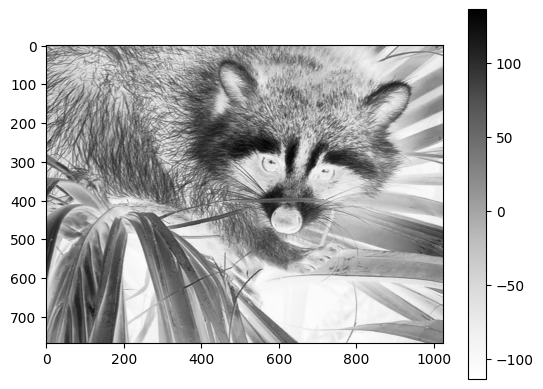

In [ ]:
# modified from the docs
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.correlate2d.html
from scipy import signal
# Import datasets instead of misc to avoid the deprecated/removed face function error
from scipy import datasets
import numpy as np
import matplotlib.pyplot as plt

# Load the raccoon face using the updated scipy.datasets module
face = datasets.face(gray=True).astype(float) - datasets.face(gray=True).mean()
plt.imshow(face, cmap="Greys")
plt.colorbar()

All a convolution is is a "template matching" process; we give it a "mini-image", and it searches for instances of this mini-image in a larger image. Here, let's extract the right eye of the raccoon to use as a template.

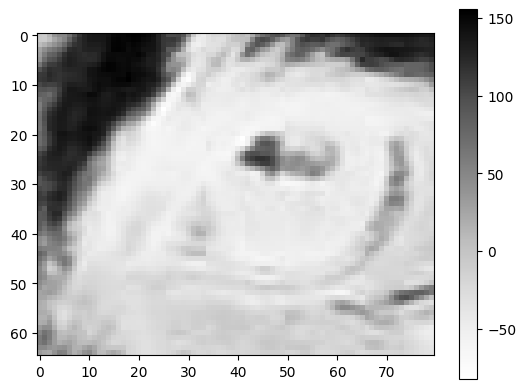

In [ ]:
template = face[300:365, 670:750]
template -= template.mean()

plt.imshow(template, cmap="Greys")
plt.colorbar()

Now, we "convolve" this template over the image. Note that strictly speaking, in machine learning we use "cross-correlation", instead of convolution. They're both similar, but *technically speaking* a convolution searches for "upside down" instances of a template, whereas cross-correlationn searches for the template as provided. This split is primarily due to convolutions arising from the signal processing community first, and then being used in machine learning.

Tl;dr in machine learning when we say "convolution" we really mean "cross-correlation". And as we see, there is a sharp activation (darker is stronger) near the right eye of the racoon, right where the original template was taken from!

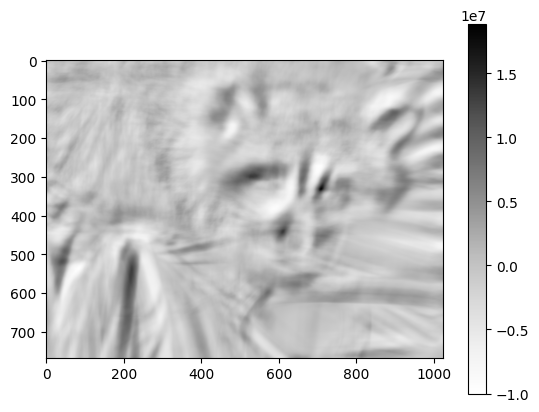

In [ ]:
corr = signal.correlate2d(face, template, boundary='symm', mode='same')
plt.imshow(corr, cmap="Greys")
plt.colorbar()

**Questions 2a**:
* What *is* this image? Why are there strong activations in locations other than the right eye (where the template is from), such as the left eye and the nose?

Answer here.

We could also try other "filters": the following is known as the Sobel operator, a classic edge detector in computer vision:

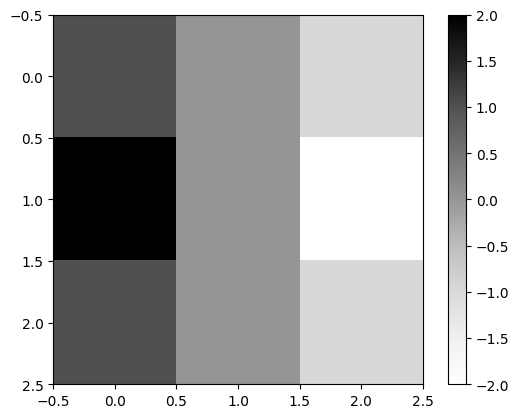

In [ ]:
template = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])

plt.imshow(template, cmap="Greys")
plt.colorbar()

When applied over the original image, we have:

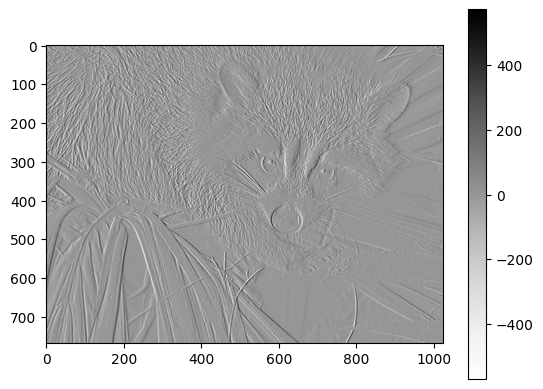

In [ ]:
corr = signal.correlate2d(face, template, boundary='symm', mode='same')
plt.imshow(corr, cmap="Greys")
plt.colorbar()

**Question 2b**: Is this a horizontal or a vertical edge detector? Why have you chosen the answer that you have?

*Hint*: Look the Sobel operator itself above (the 3x3 grid image). In which way is it oriented? What "pattern" would activate it?

Answer here.

**Question 2c**: We've only looked at grayscale images here (that is, only one channel), but most real-world images are in color! Based on the Shafkat (2018) reading, how is the match with a "filter/kernel" computed when the image has more than one "channel"?

Answer here.

### Question 3: Sobel operators + Gradients (4)

We've only looked at one of the two Sobel operators here. Read through the [wiki page](https://en.wikipedia.org/wiki/Sobel_operator) on Sobel operators, and implement the other kernel, and apply it over the image:

* What does the racoon image look like with the other kernel applied?
* How is it different from the one in question 2?

In [ ]:
%pip install jax[cpu]
%pip install Pillow
%pip install --upgrade git+https://github.com/matthias-wright/flaxmodels.git

  Cloning https://github.com/matthias-wright/flaxmodels.git to /tmp/pip-req-build-9sofsu5o
  Running command git clone --filter=blob:none --quiet https://github.com/matthias-wright/flaxmodels.git /tmp/pip-req-build-9sofsu5o
  Resolved https://github.com/matthias-wright/flaxmodels.git to commit 2c4ee0b6273b056b970063e58c00d9d5c40fa663
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Downloading: "https://www.dropbox.com/s/wx3vt76s5gpdcw5/resnet18_weights.h5" to /tmp/flaxmodels/resnet18_weights.h5


100%|██████████| 46.9M/46.9M [00:01<00:00, 27.8MiB/s]


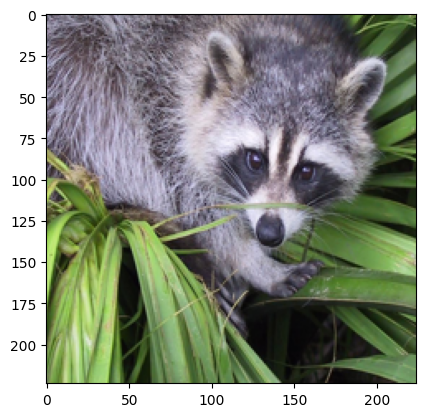

In [ ]:
from scipy import datasets
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load the color raccoon face using the updated scipy.datasets module
face = datasets.face(gray=False)
face = np.array(Image.fromarray(face).resize((224, 224)))
face = face / 255.0

plt.imshow(face)

import jax
import jax.numpy as jnp
import flaxmodels as fm

# Fix the JAX compatibility issue with older Flax versions by monkeypatching the removed function
if not hasattr(jax.core, 'get_opaque_trace_state'):
    try:
        import jax.extend.core as jec
        jax.core.get_opaque_trace_state = jec.get_opaque_trace_state
    except AttributeError:
        pass

x = jnp.expand_dims(face, axis=0)
key = jax.random.PRNGKey(0)

resnet18 = fm.ResNet18(output='activations', pretrained='imagenet')
params = resnet18.init(key, x)
activations = resnet18.apply(params, x, train=False)

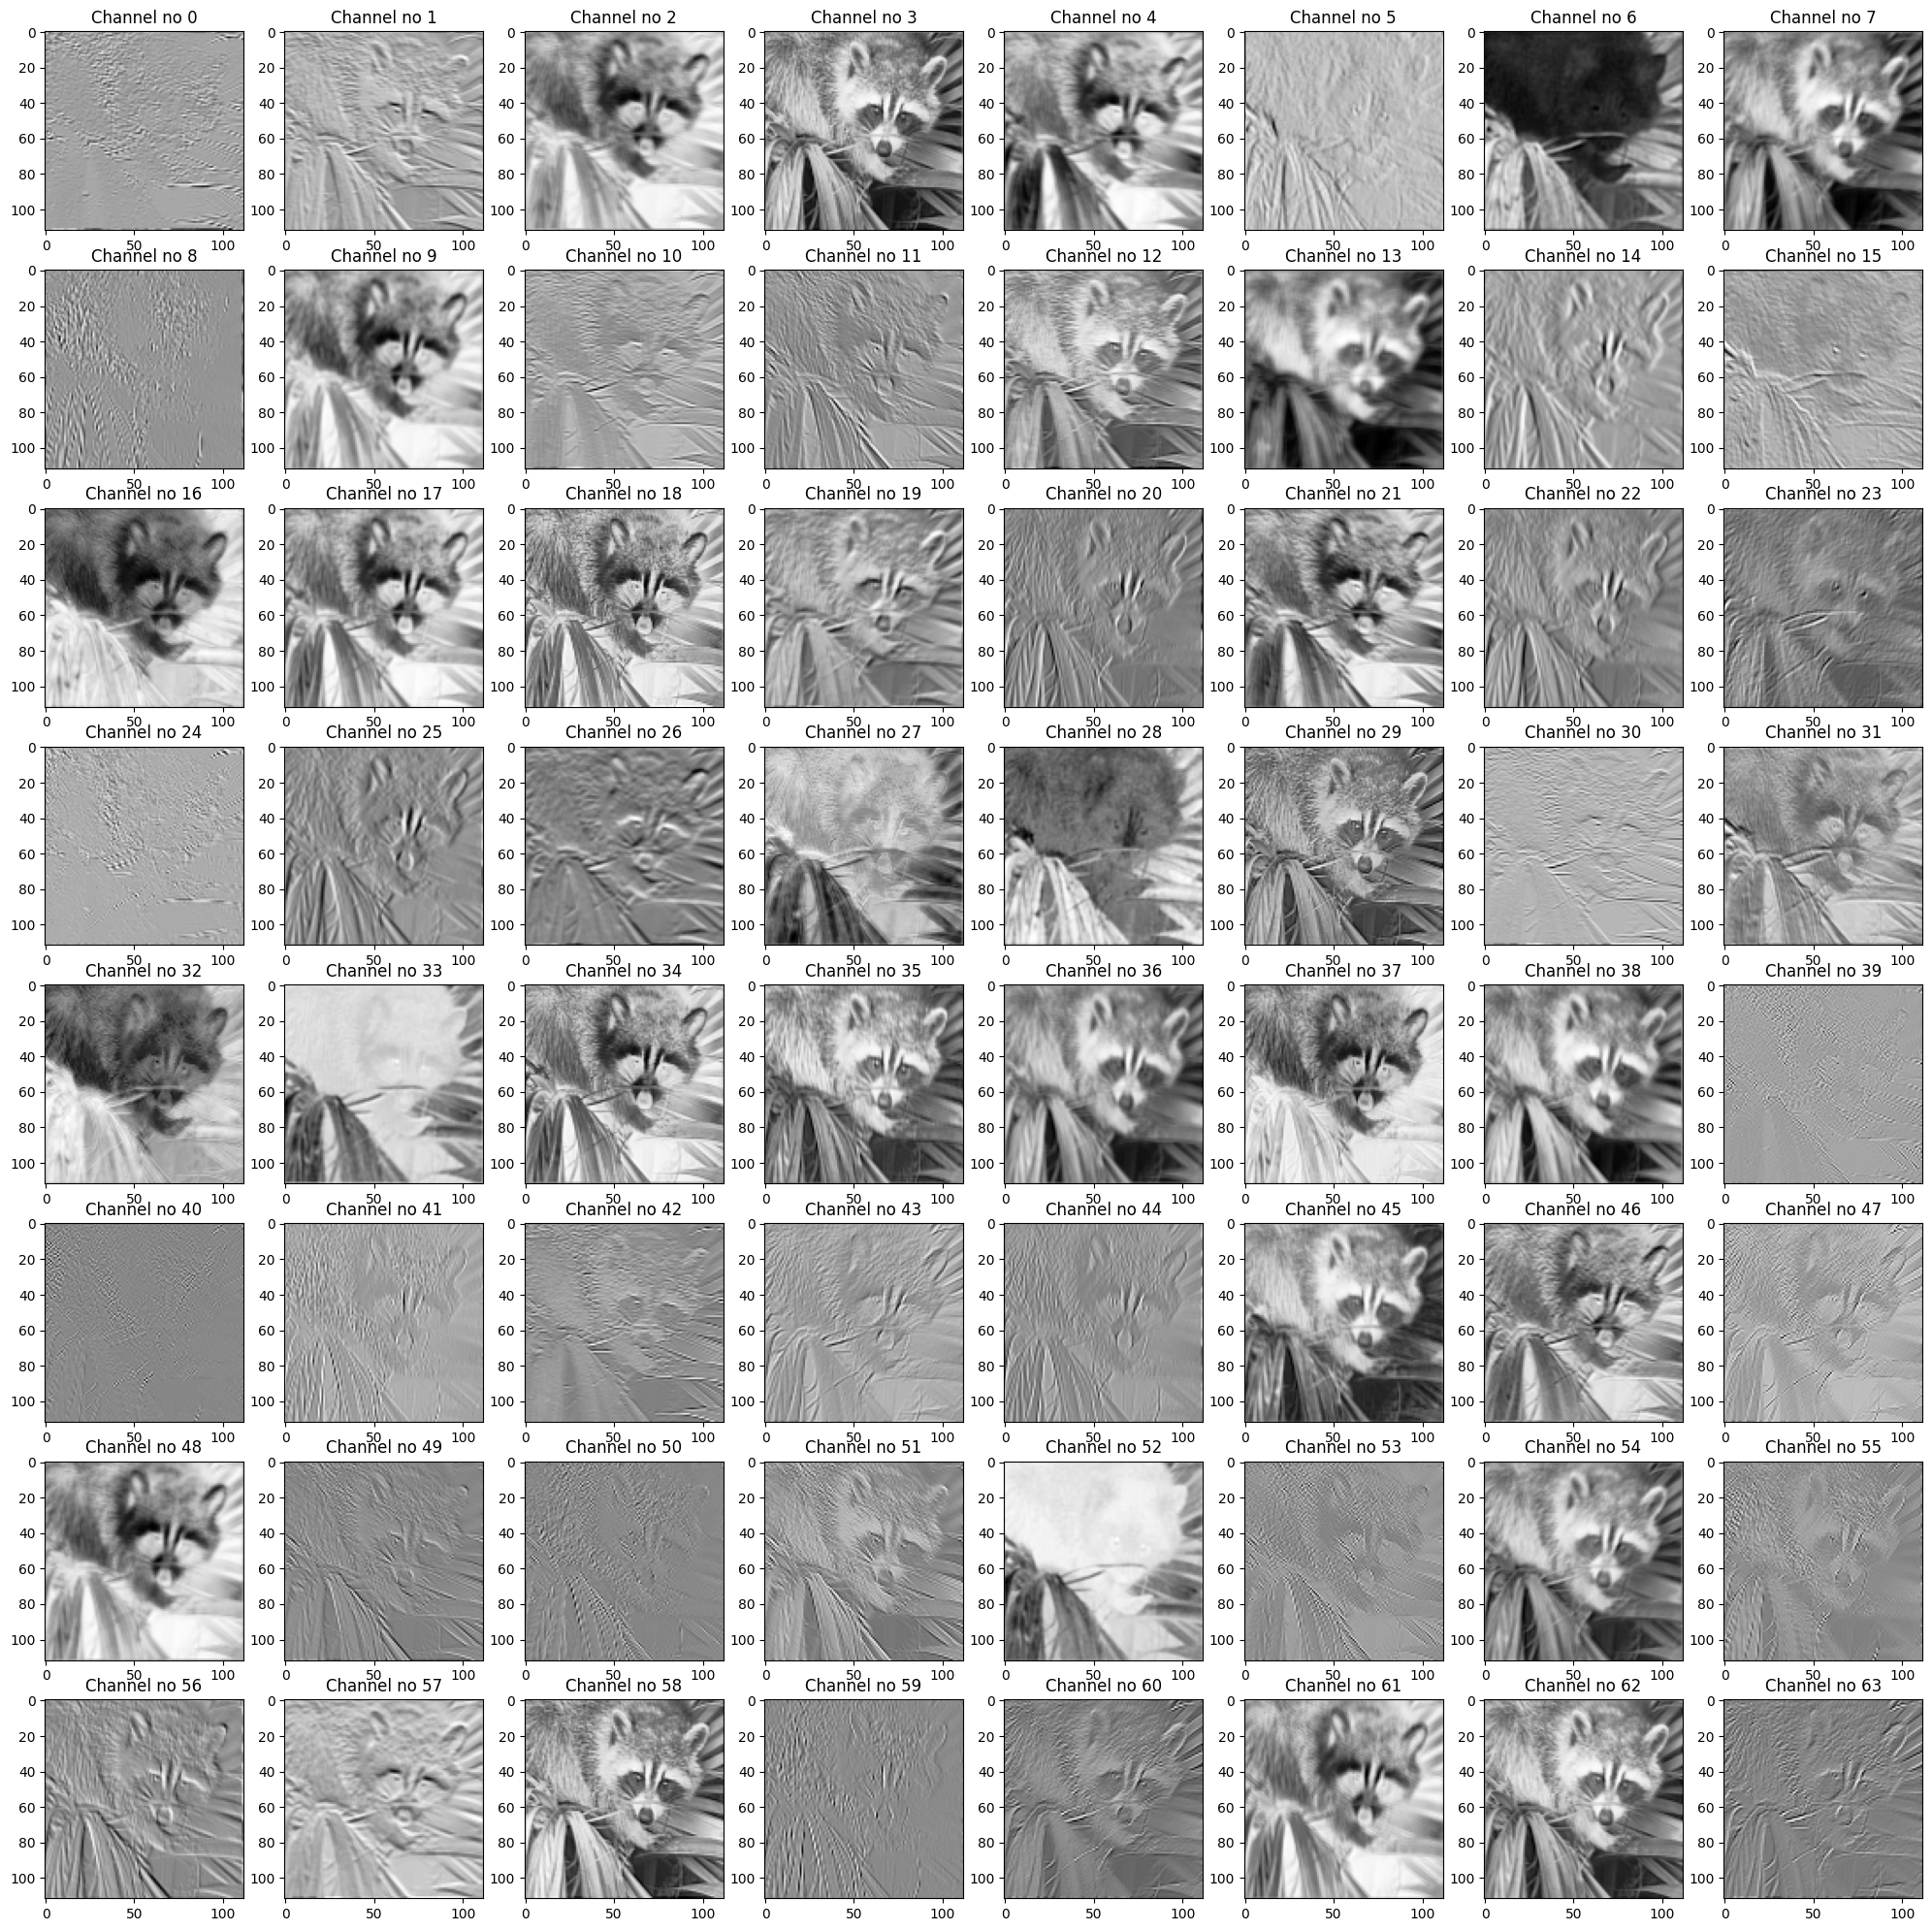

In [ ]:
fig, ax = plt.subplots(nrows=8, ncols=8, figsize=(25, 25))

for i in range(8):
    for j in range(8):
        ax[i, j].imshow(activations['conv1'][0, :, :, j + 8*i], cmap="Greys")
        ax[i, j].set_title(f"Channel no {j + 8*i}")

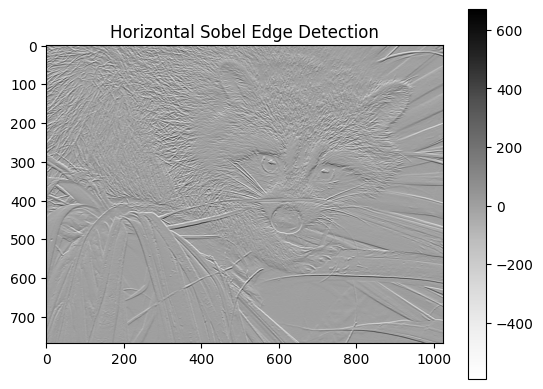

In [ ]:
from scipy import signal, datasets
import numpy as np
import matplotlib.pyplot as plt

# modern scipy.datasets instead of deprecated scipy.misc
face = datasets.face(gray=True).astype(float)
face -= face.mean()

template = np.array([
    [1, 2, 1],
    [0, 0, 0],
    [-1, -2, -1]
])

corr = signal.correlate2d(
    face, template,
    boundary='symm',
    mode='same'
)

plt.imshow(corr, cmap="Greys")
plt.colorbar()
plt.title("Horizontal Sobel Edge Detection")
plt.show()

Once you have the other filter applied, you can combine both filtered images with the following code to get the image gradient. What does it look like (visualize it with `imshow`) and how is it different from either filter in isolation?

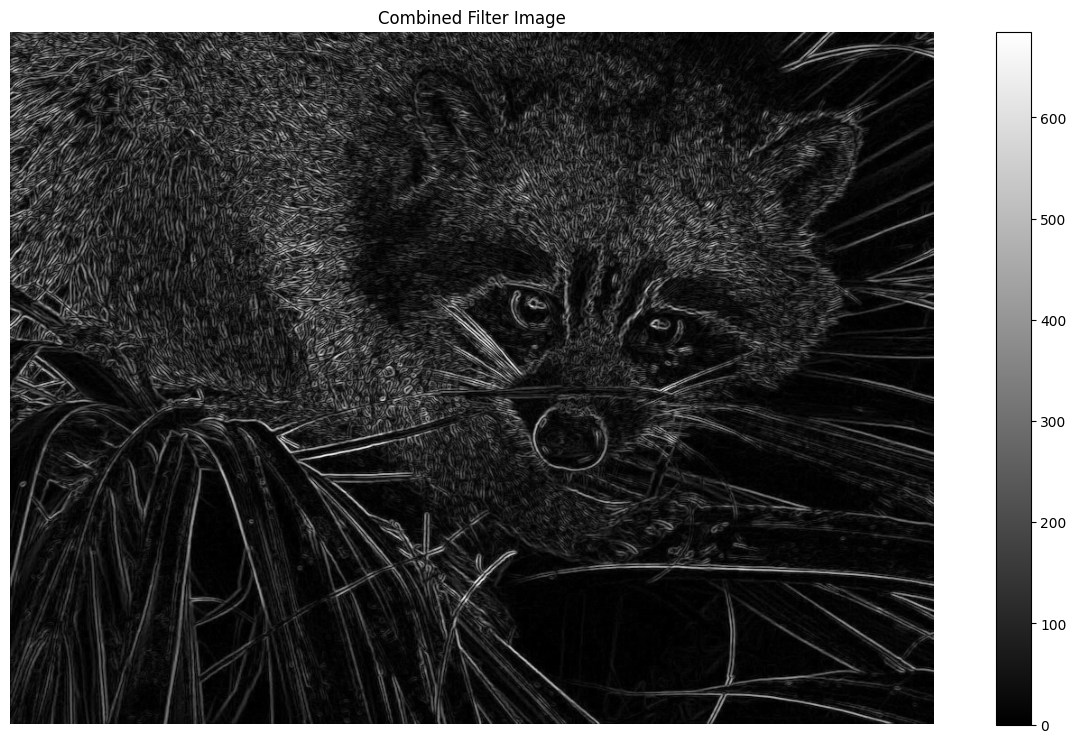

In [ ]:
# fill in here

horizontal_edge_array = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])
vertical_edge_array = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])

horizontal_edges = signal.correlate2d(face, horizontal_edge_array, boundary='symm', mode='same')
vertical_edges = signal.correlate2d(face, vertical_edge_array, boundary='symm', mode='same')

gradient = np.sqrt(horizontal_edges**2 + vertical_edges**2)

# visualize here
plt.figure(figsize=(16,9))
plt.imshow(gradient, cmap='gray')
plt.colorbar()
plt.title('Combined Filter Image')
plt.axis('off')
plt.show()

Answer here: It looks more representative of a racoon as in the features that we could barely see in either the vertical edge operator or horizontal edge operator. The fur is the most prominent since both filters have given it texture and detail which was not there at all with either operator. The eyes have insane depth. The eyes, the nose have high resolution (yes it feels like it has higher resolution due to huge detail improvement).

The new filter detects changes in pixel intensity in both vertical and horizontal directions which is combined into a square root summation of each term squared which leads to a more detailed feature image.